In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, Model

from PIL import Image

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

import seaborn as sns

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
from pathlib import Path

BASE_DIR = Path('/content/ships_data/Ships dataset')

train_img_dir = BASE_DIR / 'train' / 'images'
train_label_dir = BASE_DIR / 'train' / 'labels'

valid_img_dir = BASE_DIR / 'valid' / 'images'
valid_label_dir = BASE_DIR / 'valid' / 'labels'

test_img_dir = BASE_DIR / 'test' / 'images'
test_label_dir = BASE_DIR / 'test' / 'labels'

print("Training images:", train_img_dir.exists())
print("Training labels:", train_label_dir.exists())

print("Validation images:", valid_img_dir.exists())
print("Validation labels:", valid_label_dir.exists())

print("Testing images:", test_img_dir.exists())
print("Testing labels:", test_label_dir.exists())

Training images: True
Training labels: True
Validation images: True
Validation labels: True
Testing images: True
Testing labels: True


In [ ]:
class_names = [
    'Aircraft Carrier',
    'Bulkers',
    'Car Carrier',
    'Container Ship',
    'Cruise',
    'DDG',
    'Recreational',
    'Sailboat',
    'Submarine',
    'Tug'
]

num_classes = len(class_names)

print("Number of classes:", num_classes)

Number of classes: 10


In [ ]:
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp')

train_files = [
    f for f in os.listdir(train_img_dir)
    if f.lower().endswith(image_extensions)
]

valid_files = [
    f for f in os.listdir(valid_img_dir)
    if f.lower().endswith(image_extensions)
]

test_files = [
    f for f in os.listdir(test_img_dir)
    if f.lower().endswith(image_extensions)
]

print("Training images:", len(train_files))
print("Validation images:", len(valid_files))
print("Testing images:", len(test_files))

Training images: 7406
Validation images: 689
Testing images: 381


In [ ]:
label_files = os.listdir(train_label_dir)

print("Total label files:", len(label_files))
print("Sample label filename:", label_files[0])

with open(train_label_dir / label_files[0], 'r') as file:
    print("Label content:", file.read())

Total label files: 7406
Sample label filename: MORNING-CAROLINE-2_jpg.rf.def21b9625e38e2f13a67098347b41c2.txt
Label content: 2 0.5 0.5 1 1


In [ ]:
from collections import Counter

class_counts = Counter()

for label_file in train_label_dir.glob("*.txt"):
    with open(label_file, 'r') as file:
        line = file.readline().strip()

        if line:
            class_id = int(line.split()[0])
            class_counts[class_id] += 1

for i, name in enumerate(class_names):
    print(name, ":", class_counts[i])

Aircraft Carrier : 792
Bulkers : 256
Car Carrier : 1772
Container Ship : 832
Cruise : 778
DDG : 863
Recreational : 236
Sailboat : 328
Submarine : 746
Tug : 803


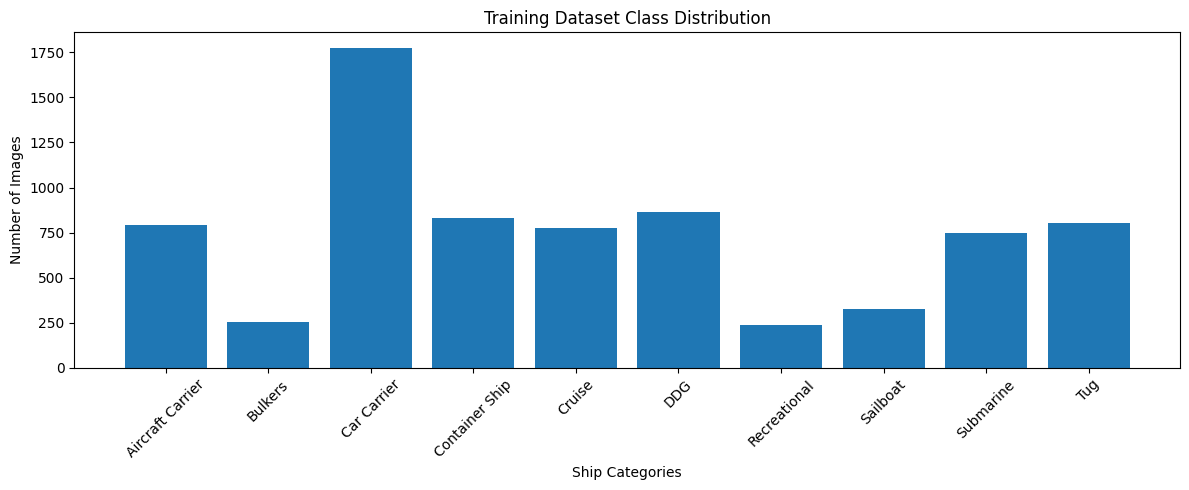

In [ ]:
plt.figure(figsize=(12, 5))

plt.bar(
    [class_names[i] for i in range(10)],
    [class_counts[i] for i in range(10)]
)

plt.xticks(rotation=45)
plt.xlabel("Ship Categories")
plt.ylabel("Number of Images")
plt.title("Training Dataset Class Distribution")
plt.tight_layout()
plt.show()


In [ ]:
IMG_SIZE = 128

print("Image size:", IMG_SIZE, "x", IMG_SIZE)

Image size: 128 x 128


In [ ]:
def load_image(image_path):

    img = Image.open(image_path).convert('RGB')

    img = img.resize((IMG_SIZE, IMG_SIZE))

    img_array = np.array(img)

    return img_array

Image shape: (128, 128, 3)
Data type: uint8


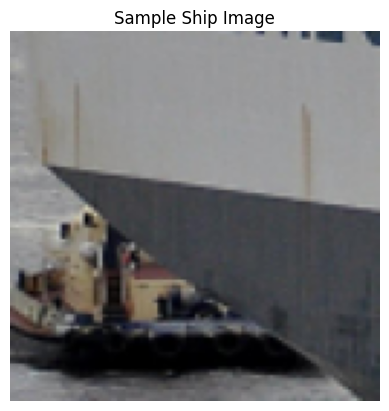

In [ ]:
sample_image_path = train_img_dir / train_files[0]

sample_image = load_image(sample_image_path)

print("Image shape:", sample_image.shape)
print("Data type:", sample_image.dtype)

plt.imshow(sample_image)
plt.title("Sample Ship Image")
plt.axis('off')
plt.show()

In [ ]:
def load_dataset(image_dir, label_dir):

    images = []
    labels = []

    for image_file in image_dir.iterdir():

        if image_file.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
            continue

        label_file = label_dir / (image_file.stem + '.txt')

        if not label_file.exists():
            continue

        with open(label_file, 'r') as file:
            line = file.readline().strip()

        if not line:
            continue

        class_id = int(line.split()[0])

        if class_id < 0 or class_id >= num_classes:
            continue

        img = load_image(image_file)

        images.append(img)
        labels.append(class_id)

    return np.array(images), np.array(labels)

In [ ]:
X_train, y_train = load_dataset(
    train_img_dir,
    train_label_dir
)

print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

Training images shape: (7406, 128, 128, 3)
Training labels shape: (7406,)


In [ ]:
X_valid, y_valid = load_dataset(
    valid_img_dir,
    valid_label_dir
)

print("Validation images shape:", X_valid.shape)
print("Validation labels shape:", y_valid.shape)

Validation images shape: (689, 128, 128, 3)
Validation labels shape: (689,)


In [ ]:
X_test, y_test = load_dataset(
    test_img_dir,
    test_label_dir
)

print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Testing images shape: (381, 128, 128, 3)
Testing labels shape: (381,)


In [ ]:
X_train = X_train.astype('float32') / 255.0
X_valid = X_valid.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [ ]:
model = tf.keras.Sequential([

    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(num_classes, activation='softmax')
])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [21]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    epochs=5,
    batch_size=32
)

Epoch 1/5
232/232 ━━━━━━━━━━━━━━━━━━━━ 253s 1s/step - accuracy: 0.7513 - loss: 0.7988 - val_accuracy: 0.8171 - val_loss: 0.5634
Epoch 2/5
232/232 ━━━━━━━━━━━━━━━━━━━━ 270s 1s/step - accuracy: 0.8235 - loss: 0.5502 - val_accuracy: 0.8520 - val_loss: 0.4973
Epoch 3/5
232/232 ━━━━━━━━━━━━━━━━━━━━ 248s 1s/step - accuracy: 0.8782 - loss: 0.3836 - val_accuracy: 0.8534 - val_loss: 0.5217
Epoch 4/5
232/232 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.9107 - loss: 0.2770 - val_accuracy: 0.8723 - val_loss: 0.4588
Epoch 5/5
232/232 ━━━━━━━━━━━━━━━━━━━━ 271s 1s/step - accuracy: 0.9313 - loss: 0.2125 - val_accuracy: 0.8534 - val_loss: 0.5105


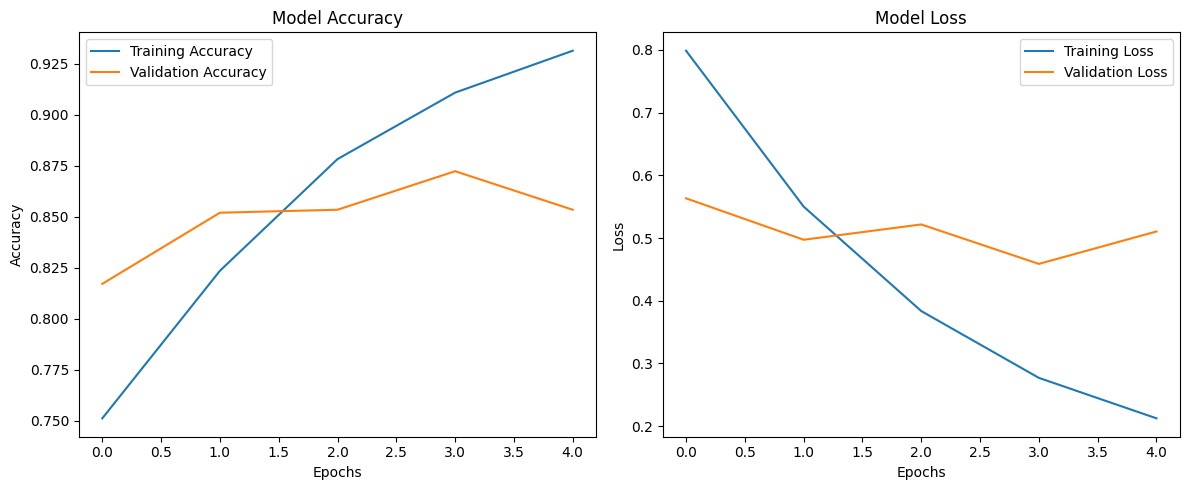

In [22]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 342ms/step - accuracy: 0.9081 - loss: 0.4129
Test Accuracy: 90.81364870071411 %
Test Loss: 0.41288304328918457


12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 639ms/step


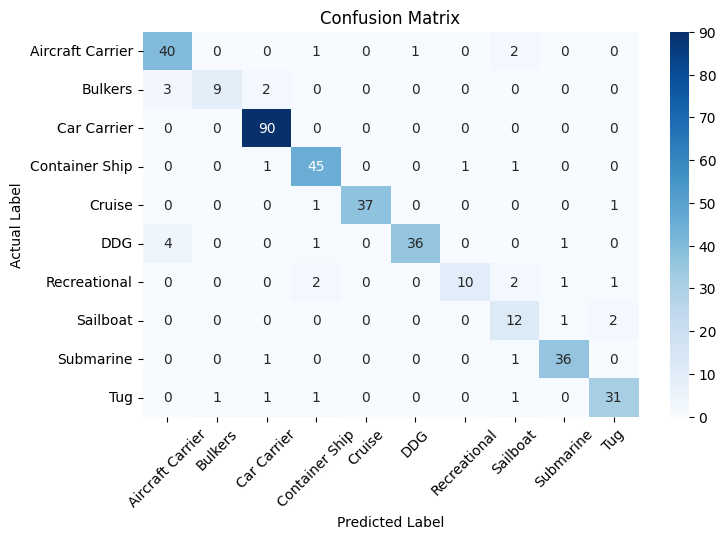

In [27]:
from sklearn.metrics import confusion_matrix

y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [28]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

                  precision    recall  f1-score   support

Aircraft Carrier       0.85      0.91      0.88        44
         Bulkers       0.90      0.64      0.75        14
     Car Carrier       0.95      1.00      0.97        90
  Container Ship       0.88      0.94      0.91        48
          Cruise       1.00      0.95      0.97        39
             DDG       0.97      0.86      0.91        42
    Recreational       0.91      0.62      0.74        16
        Sailboat       0.63      0.80      0.71        15
       Submarine       0.92      0.95      0.94        38
             Tug       0.89      0.89      0.89        35

        accuracy                           0.91       381
       macro avg       0.89      0.86      0.87       381
    weighted avg       0.91      0.91      0.91       381

